# 3. Trend rule and learned model

This notebook reads `data/processed/weekly.csv` and saves the positions and the bagging results in `data/processed/`.

Steps:
1. Load the weekly table up to the last test year
2. Baseline: sign of the factor's 52-week total return, held the following week
3. Inputs and target for the model
4. Bagging, walk-forward: train on all years before Y, test on year Y, from 2007 to 2026 (2024 to 2026 is the holdout, run once at the end)
5. Returns after costs
6. Checks: no look-ahead, no week after the last test year, overfitting alarm, shuffled-target test

In [1]:
# JupyterLab on Nuvolos starts the kernel in /files, while VS Code starts it in the notebook's
# folder. The notebooks need to run from code/ to find helpers.py and ../data, so this cell
# looks for that folder and moves into it.
import os
from pathlib import Path

if not Path("helpers.py").exists():
    found = [p.parent for p in Path.cwd().glob("**/code/helpers.py")
             if (p.parent / "05_figures.ipynb").exists()]
    if len(found) != 1:
        raise FileNotFoundError(f"Cannot find a single project code folder under {Path.cwd()}: {found}")
    os.chdir(found[0])
print("Working directory:", Path.cwd())

Working directory: /Users/robertoberardi/Desktop/HEC/3 Semester/ada-fx-project/trend-following-fx-risk-factor/code


In [2]:
import numpy as np
import pandas as pd
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

import helpers

np.random.seed(helpers.SEED)

## 1. Load the weekly table

In [3]:
weekly = pd.read_csv(f"{helpers.PROCESSED}/weekly.csv", index_col=0, parse_dates=True)

# Keep the weeks up to the last test year (set in helpers.py). The holdout years 2024 to 2026
# were added only once, at the very end of the project.
weekly = weekly[weekly.index.year <= helpers.LAST_TEST_YEAR]

factor = weekly["factor"]
print("Weeks used here:", len(weekly), "from", weekly.index[0].date(), "to", weekly.index[-1].date())

Weeks used here: 1453 from 1999-01-15 to 2026-11-13


## 2. Baseline rule

In [4]:
# The factor's total return over the last 52 weeks. Positive = the trend is up.
trend_52w = (1 + factor).rolling(52).apply(np.prod, raw=True) - 1

# Position: +1 (long) if the 52-week trend is positive, -1 (short) if negative.
# The signal is known at the Friday close of week t, so it earns week t+1's return:
# we shift the position forward by one week, so there is no look-ahead.
pos_rule = np.sign(trend_52w).shift(1).rename("pos_rule")

print("First week with a position:", pos_rule.dropna().index[0].date())
print(pos_rule.value_counts().to_string())

First week with a position: 2000-01-14
pos_rule
 1.0    957
-1.0    444


## 3. Inputs and target

In [5]:
# Inputs known at the Friday close of each week t:
# the factor's total return over 1, 4, 13 and 52 weeks, carry, VIX, 4-week VIX change.
X = pd.DataFrame({
    "ret_1w": factor,
    "ret_4w": (1 + factor).rolling(4).apply(np.prod, raw=True) - 1,
    "ret_13w": (1 + factor).rolling(13).apply(np.prod, raw=True) - 1,
    "ret_52w": trend_52w,
    "carry": weekly["carry"],
    "vix": weekly["VIX"],
    "vix_change_4w": weekly["VIX"].diff(4),
})

# Target: does the factor go up NEXT week? (1 = up, 0 = down)
y = (factor.shift(-1) > 0).astype(int).rename("up_next_week")

# Drop the rows where an input (first 52 weeks) or the target (last week) is missing
valid = X.dropna().index.intersection(y[factor.shift(-1).notna()].index)
X, y = X.loc[valid], y.loc[valid]
print("Rows for the model:", len(X), "from", X.index[0].date(), "to", X.index[-1].date())
X.tail(3)

Rows for the model: 1401 from 2000-01-07 to 2026-11-06


,ret_1w,ret_4w,ret_13w,ret_52w,carry,vix,vix_change_4w
2026-10-23,-0.001930,-0.008334,-0.017633,0.030835,1.092556,19.45,4.58
2026-10-30,0.003346,0.001658,-0.009485,0.031071,1.092556,19.42,4.11
2026-11-06,-0.002042,-0.001164,-0.008350,0.033116,1.092052,25.64,10.80


## 4. Bagging, walk-forward

In [6]:
# For each test year Y (2007 to 2026):
#   - train on all weeks before Y
#   - try the 6 setting combinations, scored on the last 2 years of the training window
#   - refit the best on the whole training window, predict year Y
settings = [(trees, depth) for trees in (100, 300) for depth in (2, 3, 5)]

def make_model(trees, depth):
    return BaggingClassifier(
        DecisionTreeClassifier(max_depth=depth, random_state=helpers.SEED),
        n_estimators=trees, random_state=helpers.SEED)

all_preds = []
train_accs, test_accs = [], []
for year in range(helpers.FIRST_TEST_YEAR, helpers.LAST_TEST_YEAR + 1):
    # The target is NEXT week's move, so the last training week's label is the first test
    # week. We drop that one week ("purge") so no test information leaks into training.
    train = X.index[X.index.year < year][:-1]
    test = X.index[X.index.year == year]

    # Inner split for tuning: the last 2 years of the training window (purged the same way)
    inner_train = train[train.year < year - 2][:-1]
    inner_val = train[train.year >= year - 2]
    best_score, best_setting = -1.0, None
    for trees, depth in settings:
        model = make_model(trees, depth).fit(X.loc[inner_train], y.loc[inner_train])
        score = (model.predict(X.loc[inner_val]) == y.loc[inner_val]).mean()
        if score > best_score:
            best_score, best_setting = score, (trees, depth)

    # Refit the best setting on the full training window, predict the test year
    model = make_model(*best_setting).fit(X.loc[train], y.loc[train])
    all_preds.append(pd.Series(model.predict(X.loc[test]), index=test))
    train_accs.append((model.predict(X.loc[train]) == y.loc[train]).mean())
    test_accs.append((all_preds[-1] == y.loc[test]).mean())
    print(f"{year}: trees={best_setting[0]:3d} depth={best_setting[1]}  "
          f"train acc {train_accs[-1]:.3f}  test acc {test_accs[-1]:.3f}")

pred = pd.concat(all_preds)
print(f"\nOverall test accuracy: {(pred == y.loc[pred.index]).mean():.3f}")
# The trivial benchmark: always predict the more frequent outcome (up)
print(f"Always predicting 'up' would score: {y.loc[pred.index].mean():.3f}")

# Save for the figures notebook: accuracy per year, confusion counts, and which inputs
# the last model relied on (average importance over its trees)
years = list(range(helpers.FIRST_TEST_YEAR, helpers.LAST_TEST_YEAR + 1))
truth = y.loc[pred.index]
results = pd.DataFrame({"year": years, "train_acc": train_accs, "test_acc": test_accs})
results["n_test"] = [int((pred.index.year == yr).sum()) for yr in years]
results.to_csv(f"{helpers.PROCESSED}/bagging_results.csv", index=False)
confusion = pd.crosstab(truth.rename("actual"), pred.rename("predicted"))
confusion.to_csv(f"{helpers.PROCESSED}/bagging_confusion.csv")
importance = pd.Series(np.mean([t.feature_importances_ for t in model.estimators_], axis=0),
                       index=X.columns).sort_values(ascending=False)
importance.rename("importance").to_csv(f"{helpers.PROCESSED}/bagging_importance.csv")
print(confusion)

2007: trees=100 depth=2  train acc 0.632  test acc 0.577
2008: trees=300 depth=2  train acc 0.630  test acc 0.519
2009: trees=100 depth=5  train acc 0.825  test acc 0.500
2010: trees=100 depth=2  train acc 0.627  test acc 0.453
2011: trees=300 depth=5  train acc 0.806  test acc 0.385
2012: trees=100 depth=3  train acc 0.690  test acc 0.423
2013: trees=100 depth=3  train acc 0.688  test acc 0.500
2014: trees=100 depth=5  train acc 0.775  test acc 0.500
2015: trees=100 depth=3  train acc 0.649  test acc 0.519
2016: trees=100 depth=3  train acc 0.653  test acc 0.547
2017: trees=300 depth=5  train acc 0.769  test acc 0.462
2018: trees=300 depth=3  train acc 0.661  test acc 0.500
2019: trees=100 depth=2  train acc 0.612  test acc 0.481
2020: trees=300 depth=3  train acc 0.645  test acc 0.596
2021: trees=100 depth=5  train acc 0.733  test acc 0.547
2022: trees=100 depth=5  train acc 0.737  test acc 0.500
2023: trees=100 depth=5  train acc 0.718  test acc 0.558
2024: trees=100 depth=2  train 

## 5. Returns after costs

Test period: 2007-01-12 to 2026-11-06
rule   Sharpe  0.12   max drawdown -17.2%   yearly turnover 2.2 switches
model  Sharpe  0.20   max drawdown -26.8%   yearly turnover 7.4 switches


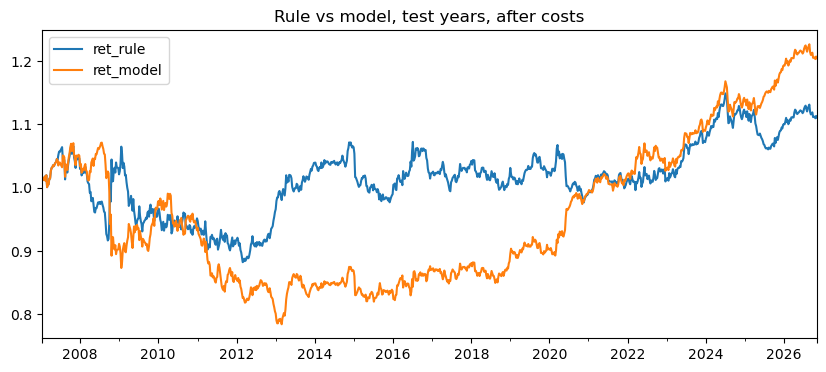

In [7]:
# The prediction for week t+1 is made at the close of week t.
# Position: +1 if the model says up, -1 if down. Shift by one week, like the rule.
pos_model = (2 * pred - 1).shift(1).rename("pos_model")

# Align everything on the weeks where both strategies have a position
start = pos_model.dropna().index[0]
table = pd.DataFrame({
    "factor": factor,
    "pos_rule": pos_rule,
    "pos_model": pos_model,
}).loc[start:str(helpers.LAST_TEST_YEAR)].dropna()

# Cost: 3 bp per unit of position change (a switch from long to short = 2 units = 6 bp)
for name in ("rule", "model"):
    pos = table[f"pos_{name}"]
    cost = helpers.COST_BP / 1e4 * pos.diff().abs().fillna(0)
    table[f"ret_{name}"] = pos * table["factor"] - cost

table[["ret_rule", "ret_model"]].to_csv(f"{helpers.PROCESSED}/positions_test_years.csv")

print("Test period:", table.index[0].date(), "to", table.index[-1].date())
for name in ("rule", "model"):
    r = table[f"ret_{name}"]
    print(f"{name:6s} Sharpe {helpers.sharpe_ratio(r):5.2f}   "
          f"max drawdown {helpers.max_drawdown(r):6.1%}   "
          f"yearly turnover {table[f'pos_{name}'].diff().abs().sum() / 2 / (len(table)/52):.1f} switches")
(1 + table[["ret_rule", "ret_model"]]).cumprod().plot(figsize=(10, 4), title="Rule vs model, test years, after costs");

## 6. Checks

In [8]:
# Checks.

# No look-ahead: both positions are shifted one week after their signal
assert pos_rule.index.equals(np.sign(trend_52w).index), "Rule position index mismatch"

# No week after the last test year is used
assert X.index.max().year <= helpers.LAST_TEST_YEAR, "Holdout weeks inside the inputs"
assert table.index.max().year <= helpers.LAST_TEST_YEAR, "Holdout weeks inside the results"

# Overfitting alarm: training accuracy far above test accuracy is a warning, not an error
gap = np.mean(train_accs) - np.mean(test_accs)
print(f"Average train accuracy {np.mean(train_accs):.3f}, test {np.mean(test_accs):.3f}, gap {gap:.3f}")
if gap > 0.15:
    print("WARNING: large gap between train and test accuracy, the model memorises noise")

# Shuffled-target test: with random targets the model should be near a coin flip out of sample
rng = np.random.default_rng(helpers.SEED)
y_shuffled = pd.Series(rng.permutation(y.values), index=y.index)
train = X.index[X.index.year < 2020]
test = X.index[(X.index.year >= 2020) & (X.index.year <= 2023)]
model = make_model(100, 3).fit(X.loc[train], y_shuffled.loc[train])
shuffled_acc = (model.predict(X.loc[test]) == y_shuffled.loc[test]).mean()
print(f"Accuracy on shuffled targets: {shuffled_acc:.3f} (should be close to 0.5)")
assert abs(shuffled_acc - 0.5) < 0.1, "Shuffled-target test failed: the pipeline leaks information"

print("\nAll checks passed")

Average train accuracy 0.680, test 0.516, gap 0.164
Accuracy on shuffled targets: 0.545 (should be close to 0.5)

All checks passed
